# Совместный EDA котировок и новостей


## 1. Загрузка и подготовка данных

Загружаем данные

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import pymorphy3
from functools import lru_cache
from sklearn.feature_extraction.text import CountVectorizer

TZ = "Europe/Moscow"
LONG_GAP_DAYS = 7
REACTION_HORIZONS = (1, 3, 8)
MIN_BASELINE_COUNT = 20
RETURN_HORIZON = 3
RETURN_SPIKE_THRESHOLD = 3
TURNOVER_SPIKE_THRESHOLD = 5
TEXT_HORIZON = 3
TEXT_MIN_DF = 5

TEXT_STOP_WORDS = {
    "и", "в", "во", "на", "по", "с", "со", "из",
    "за", "к", "от", "для", "о", "об", "у",
    "до", "при", "а", "но", "что", "как",
    "это", "быть", "свой", "год",
    "млрд", "млн", "тысяча", "рубль",
    "доллар", "евро", "процент"
}

COMPANIES = {
    "AFKS": r"\bафк\s+[«\"]?система\b",
    "AFLT": r"\bаэрофлот\w*\b",
    "ALRS": r"\bалрос\w*\b",
    "BSPB": r'\b(?:бспб|bspb)\b|\bбанк\w*\s*[«"„]?\s*санкт[-\s]*петербург\w*\b',
    "CBOM": r"\b(?:мкб|московск\w*\s+кредитн\w*\s+банк\w*)\b",
    "CHMF": r"\bсеверстал\w*\b",
    "CNRU": r"\b(?:циан|cian)\b",
    "DOMRF": r"(?<!\w)дом[.\s-]?рф(?!\w)",
    "ENPG": r"(?<!\w)(?:en\+\s*group|эн\+|эн\s+плюс)(?!\w)",
    "FLOT": r"\bсовкомфлот\w*\b",
    "GAZP": r"\bгазпром\w*\b",
    "GMKN": r"\b(?:норникел\w*|норильск\w*\s+никел\w*)\b",
    "HEAD": r"\b(?:х[еэ]дхантер\w*|headhunter)\b",
    "IRAO": r"\bинтер\s*рао\b",
    "LKOH": r"\b(?:лукойл\w*|lukoil)\b",
    "MAGN": r"\b(?:ммк|магнитогорск\w*\s+металлургическ\w*\s+комбинат\w*)\b",
    "MDMG": r"\b(?:мать\s+и\s+дитя|мд\s+медикал|md\s+medical)\b",
    "MOEX": r"\b(?:мосбирж\w*|московск\w*\s+бирж\w*|moex)\b",
    "MTSS": r"\bмтс\b",
    "NLMK": r"\bнлмк\b",
    "NVTK": r"\b(?:новатэк\w*|novatek)\b",
    "OZON": r"\b(?:озон|ozon)\b",
    "PHOR": r"\bфосагро\b",
    "PLZL": r"\bполюс\w*\b",
    "POSI": r"\b(?:позитив\s+технолоджиз|positive\s+technologies|групп\w*\s+позитив)\b",
    "RAGR": r"\bрусагро\b",
    "RENI": r"\bренессанс\s+страховани\w*\b",
    "ROSN": r"\bроснефт\w*\b",
    "RTKM": r"\bростелеком\w*\b",
    "RUAL": r"\bрусал\w*\b",
    "SBER": r"\b(?:сбербанк\w*|сбер|sber)\b",
    "SNGS": r"\bсургутнефт\w*\b",
    "SVCB": r"\bсовкомбанк\w*\b",
    "T": r"\b(?:тинькофф\w*|т[ -]?банк\w*|т[ -]?технологи\w*|ткс[ -]?холдинг\w*)\b",
    "TATN": r"\bтатнефт\w*\b",
    "TRNFP": r"\bтранснефт\w*\b",
    "UGLD": r"\b(?:югк|южуралзолот\w*|южн\w*\s+урал\w*\s+золот\w*)\b",
    "VKCO": r"\b(?:vk|вк|вконтакте|mail\.ru(?:\s+group)?)\b",
    "VTBR": r"\bвтб\b",
    "X5": r"\b(?:x5|х5|пят[её]рочк\w*|перекр[её]сток\w*)\b",
    "YDEX": r"\b(?:яндекс\w*|yandex)\b",
}

COMPANIES["SBERP"] = COMPANIES["SBER"]
COMPANIES["TATNP"] = COMPANIES["TATN"]
COMPANIES["SNGSP"] = COMPANIES["SNGS"]

stocks = pd.read_csv("data/stocks.csv")
news = pd.read_csv("data/news_final.csv")

stocks["begin"] = pd.to_datetime(stocks["begin"]).dt.tz_localize(TZ)
stocks["end"] = pd.to_datetime(stocks["end"]).dt.tz_localize(TZ)

news["datetime"] = (
    pd.to_datetime(news["datetime"], format="mixed", utc=True)
    .dt.tz_convert(TZ)
)

stocks = stocks.sort_values(["ticker", "begin"]).reset_index(drop=True)
news = news.sort_values("datetime").reset_index(drop=True)

print("Свечей:", len(stocks))
print("Новостей:", len(news))
print("Тикеров:", stocks["ticker"].nunique())

Свечей: 1006013
Новостей: 35525
Тикеров: 44


### 1.1. Рыночные показатели

Рассчитываем рыночные показатели. Считаем доходность внутри свечи, доходность относительно предыдущего закрытия без разрывов. Вторую рассчитываем только для непрерывных часовых свечей, разрывы будем анализировать отдельно

In [2]:
stocks["hours_since_previous_candle"] = (
    stocks.groupby("ticker")["begin"]
    .diff()
    .dt.total_seconds() / 3600
)

stocks["candle_return"] = (
    stocks["close"] / stocks["open"] - 1
)

stocks["hourly_return"] = (
    stocks["close"]
    / stocks.groupby("ticker")["close"].shift(1) - 1
)

stocks["hourly_return"] = stocks["hourly_return"].where(
    stocks["hours_since_previous_candle"] == 1
)

stocks["turnover_mln_rub"] = stocks["value"] / 1_000_000

display(
    stocks[
        ["ticker", "begin", "candle_return",
         "hourly_return", "hours_since_previous_candle",
         "turnover_mln_rub"]
    ].head(10)
)

,ticker,begin,candle_return,hourly_return,hours_since_previous_candle,turnover_mln_rub
0,AFKS,2020-01-03 09:00:00+03:00,0.000000,NaN,NaN,0.018300
1,AFKS,2020-01-03 10:00:00+03:00,0.003278,0.003410,1.0,23.735745
2,AFKS,2020-01-03 11:00:00+03:00,-0.001372,-0.001438,1.0,18.837303
3,AFKS,2020-01-03 12:00:00+03:00,-0.001832,-0.001832,1.0,17.150256
4,AFKS,2020-01-03 13:00:00+03:00,-0.002426,-0.002557,1.0,13.532561
5,AFKS,2020-01-03 14:00:00+03:00,0.000723,0.000197,1.0,12.058480
6,AFKS,2020-01-03 15:00:00+03:00,-0.000131,0.000131,1.0,4.598384
7,AFKS,2020-01-03 16:00:00+03:00,-0.002234,-0.002168,1.0,10.819004
8,AFKS,2020-01-03 17:00:00+03:00,-0.000132,-0.000132,1.0,37.905904
9,AFKS,2020-01-03 18:00:00+03:00,-0.003162,-0.003227,1.0,19.210607


## 2. Сопоставление новостей с акциями

Привязываем новости к акциям

In [3]:
news_matches = []

for ticker, pattern in COMPANIES.items():
    matched = news.loc[
        news["title"].str.contains(
            pattern, case=False, regex=True, na=False
        ),
        ["record_id", "datetime", "title"]
    ].copy()

    matched["ticker"] = ticker
    news_matches.append(matched)

news_stocks = pd.concat(news_matches, ignore_index=True)

news_counts = (
    news_stocks.groupby("ticker")["record_id"]
    .nunique()
    .sort_values(ascending=False)
)

display(news_counts)

print("Новостей с упоминанием компаний:",
      news_stocks["record_id"].nunique())

ticker
MOEX     4314
GAZP     2146
VTBR     1539
SBERP    1474
SBER     1474
ROSN      650
YDEX      490
LKOH      459
GMKN      410
AFLT      395
OZON      312
MTSS      295
TRNFP     265
T         247
VKCO      245
NVTK      227
RUAL      226
RTKM      222
X5        218
ALRS      197
SVCB      192
TATN      175
TATNP     175
CHMF      169
RAGR      148
AFKS      143
SNGS      142
SNGSP     142
PLZL      137
UGLD      136
IRAO      133
PHOR      125
DOMRF     125
MAGN      105
HEAD       99
NLMK       97
FLOT       86
BSPB       79
CNRU       65
POSI       38
CBOM       35
MDMG       31
ENPG       23
RENI       23
Name: record_id, dtype: int64

Новостей с упоминанием компаний: 15937


In [4]:
# Подготавливаем свечи для сопоставления
candles = stocks[
    ["ticker", "begin", "end", "candle_return", "turnover_mln_rub"]
].rename(columns={
    "begin": "reaction_start",
    "end": "reaction_end"
}).copy()

# Приводим время к одинаковой точности
candles["reaction_start"] = candles["reaction_start"].astype(
    "datetime64[ns, Europe/Moscow]"
)

events = news_stocks.copy()
events["datetime"] = events["datetime"].astype(
    "datetime64[ns, Europe/Moscow]"
)

# Находим первую полную свечу после каждой публикации
news_reactions = pd.merge_asof(
    events.sort_values("datetime"),
    candles.sort_values("reaction_start"),
    left_on="datetime",
    right_on="reaction_start",
    by="ticker",
    direction="forward"
)

# Время ожидания начала свечи после публикации
news_reactions["wait_hours"] = (
    news_reactions["reaction_start"] - news_reactions["datetime"]
).dt.total_seconds() / 3600

print("Всего соответствий:", len(news_reactions))
print("Без последующей свечи:", news_reactions["reaction_start"].isna().sum())

display(
    news_reactions[
        ["ticker", "datetime", "reaction_start",
         "wait_hours", "candle_return"]
    ].head(15)
)

display(news_reactions["wait_hours"].describe())

Всего соответствий: 18428
Без последующей свечи: 0


,ticker,datetime,reaction_start,wait_hours,candle_return
0,ROSN,2020-01-01 15:21:00+03:00,2020-01-03 09:00:00+03:00,41.650000,0.000000
1,GAZP,2020-01-02 18:06:00+03:00,2020-01-03 09:00:00+03:00,14.900000,0.000000
2,TRNFP,2020-01-03 11:43:00+03:00,2020-01-03 12:00:00+03:00,0.283333,-0.000553
3,TRNFP,2020-01-04 15:36:00+03:00,2020-01-06 10:00:00+03:00,42.400000,-0.005892
4,MOEX,2020-01-06 10:17:00+03:00,2020-01-06 11:00:00+03:00,0.716667,-0.001217
5,FLOT,2020-01-09 10:29:00+03:00,2020-10-07 09:00:00+03:00,6526.516667,0.000000
6,VTBR,2020-01-09 10:29:00+03:00,2020-01-09 11:00:00+03:00,0.516667,-0.003300
7,GAZP,2020-01-09 14:58:00+03:00,2020-01-09 15:00:00+03:00,0.033333,-0.001807
8,GAZP,2020-01-09 15:34:00+03:00,2020-01-09 16:00:00+03:00,0.433333,0.000393
9,GAZP,2020-01-09 16:47:00+03:00,2020-01-09 17:00:00+03:00,0.216667,-0.000747


count    18428.000000
mean      1050.077266
std       5078.301384
min          0.000000
25%          0.333333
50%          0.633333
75%          0.866667
max      50132.133333
Name: wait_hours, dtype: float64

wait_hours показывает сколько времени прошло от новости до начала следующей свечи тикера. Огромные среднее и масимальное говорят о том, что могли быть случаи где либо была приостановлена торговля акцией, либо просто не было данных в этот период, которые могли бы повлиять

В дальнейшем разделим наблюдения на:
- обычные торги, где реакция наступает вскоре после новости
- торги после перерыва на выходные или праздники
- длительные разрывы - их из анализа исключим

## 3. Торговые разрывы

Находим разрывы между найденными свечами. Для этого к первой свече найденной после новости назодим предыдущую и считаем гэп между ними и разделим их на группы по длительности разрыва

In [5]:
previous_candles = stocks[
    ["ticker", "begin"]
].sort_values(["ticker", "begin"]).copy()

previous_candles["previous_candle_start"] = (
    previous_candles.groupby("ticker")["begin"].shift(1)
)

previous_candles = previous_candles.rename(
    columns={"begin": "reaction_start"}
)

news_reactions = news_reactions.merge(
    previous_candles,
    on=["ticker", "reaction_start"],
    how="left",
    validate="many_to_one"
)

news_reactions["gap_before_reaction_hours"] = (
    news_reactions["reaction_start"]
    - news_reactions["previous_candle_start"]
).dt.total_seconds() / 3600

news_reactions["trading_case"] = "Перерыв между сессиями"

news_reactions.loc[
    news_reactions["previous_candle_start"].isna(),
    "trading_case"
] = "Нет предыдущей свечи"

news_reactions.loc[
    news_reactions["gap_before_reaction_hours"] > LONG_GAP_DAYS * 24,
    "trading_case"
] = "Длительный разрыв"

news_reactions.loc[
    (news_reactions["gap_before_reaction_hours"] == 1)
    & (news_reactions["wait_hours"] <= 1),
    "trading_case"
] = "Непрерывные торги"

display(news_reactions["trading_case"].value_counts())

trading_case
Непрерывные торги         15575
Перерыв между сессиями     1396
Нет предыдущей свечи       1133
Длительный разрыв           324
Name: count, dtype: int64

Видим, что подавляющая часть приходится на непрерывные торги. Остальные приходятся либо на перерывы в торгах, долгие разрывы в свечах либо на отсутствие предыдущей свечи в датасете.
Оценим время ожидания от новости до следующей свечи и проверим случаи с отсутствующей предыдущей свечей 

In [6]:
wait_stats = (
    news_reactions
    .groupby("trading_case")["wait_hours"]
    .agg(["count", "median", "mean", "max"])
    .round(2)
)

display(wait_stats)

# Проверим, с какими акциями связаны случаи
# отсутствия предыдущей свечи
first_candle_events = (
    news_reactions[
        news_reactions["trading_case"] == "Нет предыдущей свечи"
    ]
    .groupby("ticker")
    .agg(
        news_count=("record_id", "count"),
        median_wait_hours=("wait_hours", "median"),
        first_candle=("reaction_start", "min")
    )
    .sort_values("news_count", ascending=False)
)

display(first_candle_events)

,count,median,mean,max
trading_case,,,,
Длительный разрыв,324,372.38,359.29,1125.17
Непрерывные торги,15575,0.57,0.53,0.98
Нет предыдущей свечи,1133,16224.43,16944.31,50132.13
Перерыв между сессиями,1396,13.05,20.26,152.52


,news_count,median_wait_hours,first_candle
ticker,,,
YDEX,381,21060.700000,2024-07-24 09:00:00+03:00
X5,186,21954.658333,2025-01-09 09:00:00+03:00
DOMRF,107,12311.000000,2025-11-20 16:00:00+03:00
RAGR,107,14223.033333,2025-02-17 09:00:00+03:00
SVCB,91,14778.733333,2023-12-15 17:00:00+03:00
VKCO,71,6836.116667,2021-12-14 07:00:00+03:00
HEAD,70,12686.850000,2024-09-26 09:00:00+03:00
CNRU,50,13311.908333,2025-04-03 09:00:00+03:00
UGLD,30,10186.900000,2023-11-22 16:00:00+03:00


Медиана для непрерывных торгов ожидаемо низкая - новости выходят параллельно с торгами, следующие свечи наступают быстро
Для группы с перерывами между сессиями тоже ожидаемые цифры
Для тех тикеров, у которых нет предыдущих свечей новости были опубликованы задолго до первой свечи тикера - эту группу следует убрать из анализа.
Также следует исключить группу с длительными разрывами, их немного а анализ причин (приостановка торгов, СВО, корпоративные проблемы) видится проблематичным

## 4. Доходность после новостей

### 4.1. Доходность на разных горизонтах

Оценим поведение свеч на разных периодах от публикации новостей через изменение доходностей. Это пока что просто оценка изменения, необязательно, что это реакция именно на новость.
Оцениваются непрерывные свечи с первой полной свечи после публикации (три свечи подряд для 3-часового окн, или 8 для 8-часового), если следующей свечи нет, будет NaN

In [7]:
# Оставляем новости, опубликованные во время непрерывных торгов
continuous_events = news_reactions.loc[
    news_reactions["trading_case"] == "Непрерывные торги"
].copy()

candles = stocks.sort_values(["ticker", "begin"]).copy()
grouped = candles.groupby("ticker")

for h in REACTION_HORIZONS:
    final_close = grouped["close"].shift(-(h - 1))

    # Проверяем непрерывность всех свечей внутри окна
    valid = pd.Series(True, index=candles.index)

    for k in range(1, h):
        gap = (
            grouped["begin"].shift(-k)
            - grouped["begin"].shift(-(k - 1))
        ).dt.total_seconds() / 3600

        valid &= gap.eq(1)

    candles[f"reaction_{h}h"] = (
        final_close / candles["open"] - 1
    ).where(valid)

reaction_columns = [
    f"reaction_{h}h" for h in REACTION_HORIZONS
]

continuous_events = continuous_events.merge(
    candles[["ticker", "begin"] + reaction_columns].rename(
        columns={"begin": "reaction_start"}
    ),
    on=["ticker", "reaction_start"],
    how="left",
    validate="many_to_one"
)

print("Количество наблюдений:", len(continuous_events))
print("\nДоступные окна реакции:")
display(continuous_events[reaction_columns].count())

print("\nРаспределение доходности, %:")
display(
    (continuous_events[reaction_columns] * 100)
    .describe()
    .round(3)
)

Количество наблюдений: 15575

Доступные окна реакции:


reaction_1h    15575
reaction_3h    14931
reaction_8h     9576
dtype: int64


Распределение доходности, %:


,reaction_1h,reaction_3h,reaction_8h
count,15575.000,14931.000,9576.000
mean,-0.026,-0.036,-0.080
std,0.932,1.205,1.794
min,-28.525,-31.428,-40.712
25%,-0.253,-0.410,-0.724
50%,-0.014,-0.019,-0.092
75%,0.214,0.334,0.539
max,42.310,23.462,33.047


Бросается в глаза, что чем шире горизонт тем сильнее изменение. Частично может объясняться меньше выборкой, но все же этот факт стоит отметить. При этом максимум именно на часовой горизонт пришелся. 

Тем не менее, это все еще не говорит о реакции именно на новость. Для оценки влияния новости оценим изменение относительно обычных изменений акции

### 4.2. Сравнение доходности с фоном

Собираем первые полные свечи после новостей. Для них помечаем признак has_news=True
Для сравнения собираем свечи, к которым не привязаны новости из выборки - у них в признаке has_news будет NaN
Собираем фоновую доходность - собираем свечи той же акции, того же года и часа и считаем для них абсолютную доходность
Для фоновой доходности проверяем что есть необходимое количество наблюдений - параметр MIN_BASELINE_COUNT.
И сравниваем полученную после новости доходность с фоновой

In [8]:
# Отмечаем свечи, к которым привязаны новости
event_starts = (
    continuous_events[["ticker", "reaction_start"]]
    .drop_duplicates()
    .rename(columns={"reaction_start": "begin"})
    .assign(has_news=True)
)

candles = (
    candles
    .drop(
        columns=["has_news", "has_news_x", "has_news_y"],
        errors="ignore"
    )
    .merge(
        event_starts,
        on=["ticker", "begin"],
        how="left",
        validate="many_to_one"
    )
)

candles["year"] = candles["begin"].dt.year
candles["hour"] = candles["begin"].dt.hour

continuous_events["year"] = continuous_events["reaction_start"].dt.year
continuous_events["hour"] = continuous_events["reaction_start"].dt.hour

background = candles[candles["has_news"].isna()]

results = []
baselines = {}

for h in REACTION_HORIZONS:
    col = f"reaction_{h}h"

    baseline = (
        background.groupby(["ticker", "year", "hour"])[col]
        .agg(
            baseline_abs=lambda x: x.abs().mean(),
            baseline_count="count"
        )
        .reset_index()
    )
    baselines[h] = baseline

    comparison = continuous_events.merge(
        baseline,
        on=["ticker", "year", "hour"],
        how="left"
    )

    comparison = comparison[
        comparison[col].notna()
        & comparison["baseline_count"].ge(MIN_BASELINE_COUNT)
    ]

    news_abs = comparison[col].abs().mean()
    baseline_abs = comparison["baseline_abs"].mean()

    results.append({
        "horizon": h,
        "news_count": len(comparison),
        "news_abs_%": news_abs * 100,
        "baseline_abs_%": baseline_abs * 100,
        "ratio": news_abs / baseline_abs
    })

display(pd.DataFrame(results).round(3))

,horizon,news_count,news_abs_%,baseline_abs_%,ratio
0,1,14930,0.415,0.331,1.255
1,3,14288,0.632,0.524,1.207
2,8,8936,1.014,0.883,1.149


### 4.3. Проверка на одинаковой выборке

Видно, что изменение доходности есть и изменение достаточно существенное. При этом видим, что на 8 часовом горизонте изменение относительно фонового изменения меньше. Гипотеза такая, что вышеотмеченное увеличение доходности на горизонте 8 часов от публикации новости может быть также связано и с простым движением рынка. Также снижение может быть связано с меньшей выборкой. 

Проверим этот момент: оставим только новости, для которых есть все три горизонта и в наличии достаточно фоновых наблюдений

In [9]:
# Оставляем новости с доступными доходностями на всех горизонтах
reaction_cols = [
    f"reaction_{h}h" for h in REACTION_HORIZONS
]

common_events = continuous_events.dropna(
    subset=reaction_cols
).copy()

# Присоединяем фоновую доходность для каждого горизонта
for h in REACTION_HORIZONS:
    col = f"reaction_{h}h"

    baseline = baselines[h].rename(columns={
        "baseline_abs": f"baseline_{h}h",
        "baseline_count": f"baseline_count_{h}h"
    })

    common_events = common_events.merge(
        baseline,
        on=["ticker", "year", "hour"],
        how="left",
        validate="many_to_one"
    )

    common_events = common_events[
        common_events[f"baseline_count_{h}h"] >= MIN_BASELINE_COUNT
    ]

# Сравниваем горизонты на одной и той же выборке
common_results = []

for h in REACTION_HORIZONS:
    news_abs = common_events[f"reaction_{h}h"].abs().mean()
    baseline_abs = common_events[f"baseline_{h}h"].mean()

    common_results.append({
        "horizon": h,
        "news_count": len(common_events),
        "news_abs_%": news_abs * 100,
        "baseline_abs_%": baseline_abs * 100,
        "ratio": news_abs / baseline_abs
    })

display(pd.DataFrame(common_results).round(3))

,horizon,news_count,news_abs_%,baseline_abs_%,ratio
0,1,8936,0.453,0.361,1.255
1,3,8936,0.705,0.579,1.216
2,8,8936,1.014,0.883,1.149


Действительно, изменение после новости уменьшается относительно фоновой, так как и фоновые увеличиваются. Эта тенденция справедлива для большей части тикеров:

In [10]:
ticker_results = (
    common_events.groupby("ticker")
    .agg(
        news_count=("record_id", "count"),
        news_abs_1h=("reaction_1h", lambda x: x.abs().mean()),
        baseline_abs_1h=("baseline_1h", "mean"),
        news_abs_8h=("reaction_8h", lambda x: x.abs().mean()),
        baseline_abs_8h=("baseline_8h", "mean")
    )
)

ticker_results["ratio_1h"] = (
    ticker_results["news_abs_1h"]
    / ticker_results["baseline_abs_1h"]
)

ticker_results["ratio_8h"] = (
    ticker_results["news_abs_8h"]
    / ticker_results["baseline_abs_8h"]
)

ticker_results["ratio_change"] = (
    ticker_results["ratio_8h"] - ticker_results["ratio_1h"]
)

display(
    ticker_results.loc[
        ticker_results["news_count"] >= MIN_BASELINE_COUNT,
        ["news_count", "ratio_1h", "ratio_8h", "ratio_change"]
    ].sort_values("news_count", ascending=False).round(3)
)

,news_count,ratio_1h,ratio_8h,ratio_change
ticker,,,,
MOEX,1780,1.362,1.230,-0.133
VTBR,998,1.147,1.174,0.027
GAZP,954,1.341,1.069,-0.272
SBER,923,1.274,1.128,-0.146
SBERP,923,1.123,1.135,0.012
ROSN,329,0.943,1.005,0.062
AFLT,218,1.133,0.919,-0.214
LKOH,206,1.046,0.980,-0.065
GMKN,181,1.255,1.117,-0.138


### 4.4. Сильные движения доходности

Необходимо проверить насколько чаще всплески доходности после новостей встречются по сравнению с фоновыми движениями цен:

,group,count,spikes,spike_share_%
0,После новостей,12513,2186,17.47
1,Фон,533570,68093,12.76


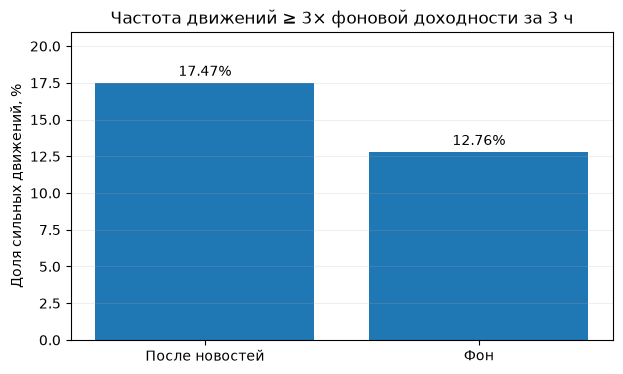

In [11]:
col = f"reaction_{RETURN_HORIZON}h"
keys = ["ticker", "year", "hour"]

# Типичная абсолютная доходность без привязанной новости
return_baseline = (
    background.groupby(keys)[col]
    .agg(
        baseline_abs=lambda x: x.abs().median(),
        baseline_count="count"
    )
    .reset_index()
)

# Уникальные свечи после новостей
news_returns = (
    continuous_events
    .drop_duplicates(["ticker", "reaction_start"])
    .merge(return_baseline, on=keys, how="left")
)

news_returns = news_returns.loc[
    news_returns["baseline_count"].ge(MIN_BASELINE_COUNT)
    & news_returns["baseline_abs"].gt(0)
    & news_returns[col].notna()
].copy()

# Фон для тех же тикеров, годов и часов
valid_groups = news_returns[keys].drop_duplicates()

background_returns = (
    background
    .merge(valid_groups, on=keys, how="inner")
    .merge(return_baseline, on=keys, how="inner")
)

background_returns = background_returns.loc[
    background_returns["baseline_count"].ge(MIN_BASELINE_COUNT)
    & background_returns["baseline_abs"].gt(0)
    & background_returns[col].notna()
].copy()

# Частота сильных движений цены
return_spike_results = []

for name, data in [
    ("После новостей", news_returns),
    ("Фон", background_returns)
]:
    spikes = (
        data[col].abs() / data["baseline_abs"]
        >= RETURN_SPIKE_THRESHOLD
    )

    return_spike_results.append({
        "group": name,
        "count": len(data),
        "spikes": spikes.sum(),
        "spike_share_%": spikes.mean() * 100
    })

display(pd.DataFrame(return_spike_results).round(2))


spike_plot = pd.DataFrame(return_spike_results)
groups = spike_plot["group"]
shares = spike_plot["spike_share_%"]

plt.figure(figsize=(7, 4))

bars = plt.bar(groups, shares)
plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.ylabel("Доля сильных движений, %")
plt.title(
    f"Частота движений ≥ {RETURN_SPIKE_THRESHOLD}× "
    f"фоновой доходности за {RETURN_HORIZON} ч"
)
plt.ylim(0, max(shares) * 1.2)
plt.grid(axis="y", alpha=0.2)
plt.show()

Увеличение доходности весьма заметно для посленовостных свечей. 

## 5. Оборот торгов

Теперь проверим реакцию объема торгов на новости.
Похожим образом сравниваем обычный оборот с оборотом после новости

In [12]:
# Рассчитываем типичный фоновый оборот
turnover_baseline = (
    background.groupby(["ticker", "year", "hour"])["turnover_mln_rub"]
    .agg(
        baseline_turnover="median",
        baseline_count="count"
    )
    .reset_index()
)

# Сопоставляем оборот после новости с фоном
turnover_comparison = continuous_events.merge(
    turnover_baseline,
    on=["ticker", "year", "hour"],
    how="left",
    validate="many_to_one"
)

# Оставляем наблюдения с достаточным количеством фоновых свечей
turnover_comparison = turnover_comparison.loc[
    turnover_comparison["baseline_count"].ge(MIN_BASELINE_COUNT)
    & turnover_comparison["baseline_turnover"].gt(0)
    & turnover_comparison["turnover_mln_rub"].notna()
].copy()

# Отношение оборота после новости к обычному обороту
turnover_comparison["turnover_ratio"] = (
    turnover_comparison["turnover_mln_rub"]
    / turnover_comparison["baseline_turnover"]
)

print("Наблюдений:", len(turnover_comparison))

display(
    turnover_comparison["turnover_ratio"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .round(3)
)

print(
    "Доля наблюдений с оборотом выше фонового:",
    round((turnover_comparison["turnover_ratio"] > 1).mean() * 100, 2),
    "%"
)

Наблюдений: 14930


count    14930.000
mean         3.172
std          7.930
min          0.023
25%          0.751
50%          1.350
75%          2.730
90%          6.323
max        312.192
Name: turnover_ratio, dtype: float64

Доля наблюдений с оборотом выше фонового: 62.93 %


Тут самое интересное, что медианная значительно выше единицы, что говорит о том, что повышенный оборот характерен для обычного наблюдения а не для отдельных экстремальных кейсов.

### 5.1. Распределение относительного оборота

Визуализируем это наблюдение:

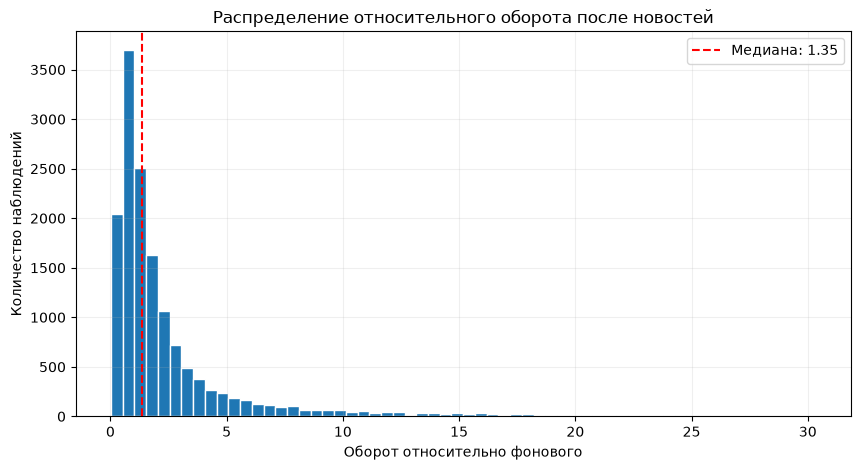

In [13]:
ratio = turnover_comparison["turnover_ratio"].dropna()

# Для читаемости графика скрываем верхний 1% выбросов
upper = ratio.quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(ratio[ratio <= upper], bins=60, edgecolor="white")
plt.axvline(
    ratio.median(),
    color="red",
    linestyle="--",
    label=f"Медиана: {ratio.median():.2f}"
)

plt.xlabel("Оборот относительно фонового")
plt.ylabel("Количество наблюдений")
plt.title("Распределение относительного оборота после новостей")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

По графику видно что для достаточно большого количества наблюдений увеличение оборота относительно фона довольно высокое. Выразим в цифрах:

In [14]:
for threshold in [2, 3, 5, 10]:
    share = (
        turnover_comparison["turnover_ratio"] >= threshold
    ).mean() * 100

    print(f"Оборот ≥ {threshold}x фонового: {share:.1f}%")

Оборот ≥ 2x фонового: 34.6%
Оборот ≥ 3x фонового: 22.5%
Оборот ≥ 5x фонового: 12.9%
Оборот ≥ 10x фонового: 5.8%


### 5.2. Сильные всплески оборота

Увеличение оборота после публикации весьма существенно для большого количества наблюдений. Но тут есть нюансы: вполне всплески могут быть и без новостей, плюс несколько новостей могут относиться к одной свече, поэтому всплеск может быть искажен.

Отдельно проверим этот момент: сравним всплеск в несколько раз после новости с подобным всплеском для обычных свечей:

,group,count,spikes,spike_share_%
0,После новостей,13122,1560,11.89
1,Фон,584338,28035,4.80


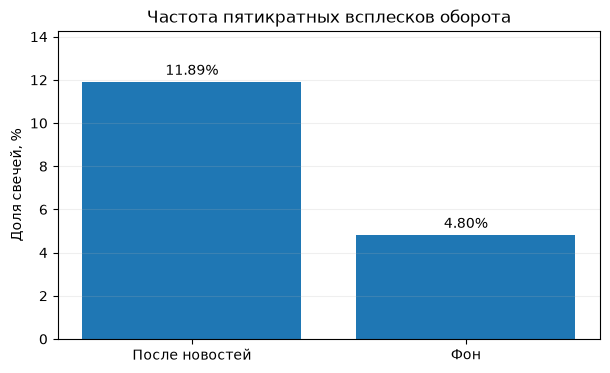

In [15]:
keys = ["ticker", "year", "hour"]

# Новостные свечи без повторений
news_turnover = turnover_comparison.drop_duplicates(
    subset=["ticker", "reaction_start"]
).copy()

# Оставляем для сравнения те же сочетания акции, года и часа
valid_groups = news_turnover[keys].drop_duplicates()

# Фоновые свечи с их обычным оборотом
background_turnover = (
    background
    .merge(turnover_baseline, on=keys, how="inner")
    .merge(valid_groups, on=keys, how="inner")
)

background_turnover = background_turnover.loc[
    background_turnover["baseline_count"].ge(MIN_BASELINE_COUNT)
    & background_turnover["baseline_turnover"].gt(0)
    & background_turnover["turnover_mln_rub"].notna()
].copy()

background_turnover["turnover_ratio"] = (
    background_turnover["turnover_mln_rub"]
    / background_turnover["baseline_turnover"]
)

# Сравниваем частоту сильных всплесков
spike_results = []

for name, data in [
    ("После новостей", news_turnover),
    ("Фон", background_turnover)
]:
    spike_results.append({
        "group": name,
        "count": len(data),
        "spikes": (data["turnover_ratio"] >= TURNOVER_SPIKE_THRESHOLD).sum(),
        "spike_share_%": (
            data["turnover_ratio"] >= TURNOVER_SPIKE_THRESHOLD
        ).mean() * 100
    })

display(pd.DataFrame(spike_results).round(2))

spike_plot = pd.DataFrame(spike_results)

plt.figure(figsize=(7, 4))

bars = plt.bar(
    spike_plot["group"],
    spike_plot["spike_share_%"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.ylabel("Доля свечей, %")
plt.title("Частота пятикратных всплесков оборота")
plt.ylim(0, spike_plot["spike_share_%"].max() * 1.2)
plt.grid(axis="y", alpha=0.2)
plt.show()

Пятикратный всплеск после новости встречается значительно чаще чем подобный всплеск без нее. И как мы видели выше, такой всплеск случается с каждой восьмой свечой. 
Итого можно констатировать, что посленовостные периоды сопровождаются ростом торговой активности.

## 6. Биграммы и рыночные показатели

Далее попробуем найти и визуализировать связь между биграммами новостей, сопоставленных с акциями и изменениями доходности и оборотов акций

In [16]:
morph = pymorphy3.MorphAnalyzer()

# Названия компаний из существующего справочника
company_regex = re.compile(
    "|".join(f"(?:{p})" for p in set(COMPANIES.values())),
    flags=re.IGNORECASE
)

@lru_cache(maxsize=100000)
def lemmatize(word):
    return morph.parse(word)[0].normal_form

def clean_title(title):
    title = company_regex.sub(" ", str(title))

    words = re.findall(r"[а-яёa-z]{2,}", title.lower())

    lemmas = [lemmatize(word) for word in words]

    return " ".join(
        word for word in lemmas
        if word not in TEXT_STOP_WORDS
    )

In [17]:
col = f"reaction_{TEXT_HORIZON}h"
keys = ["ticker", "year", "hour"]

# Средняя фоновая доходность со знаком
text_baseline = (
    background.groupby(keys)[col]
    .agg(
        baseline_return="mean",
        baseline_count="count"
    )
    .reset_index()
)

# Новости, сопоставленные с акциями
all_text_events = (
    continuous_events.loc[
        (continuous_events["ticker"] != "MOEX")
        & continuous_events[col].notna()
    ]
    .drop_duplicates(["record_id", "ticker"])
    .merge(text_baseline, on=keys, how="left")
)

all_text_events = all_text_events.loc[
    all_text_events["baseline_count"].ge(MIN_BASELINE_COUNT)
].copy()

all_text_events["excess_return_pp"] = (
    all_text_events[col] - all_text_events["baseline_return"]
) * 100

all_text_events["positive"] = (
    all_text_events["excess_return_pp"] > 0
).astype(int)

all_text_events["clean_title"] = (
    all_text_events["title"].fillna("").apply(clean_title)
)

print("Сопоставлений:", len(all_text_events))
print("Тикеров:", all_text_events["ticker"].nunique())

display(
    all_text_events[
        ["ticker", "title", "clean_title", "excess_return_pp"]
    ].head()
)

Сопоставлений: 10948
Тикеров: 43


,ticker,title,clean_title,excess_return_pp
0,TRNFP,"В ""Транснефти"" заявили, что транзит нефти чере...",заявить транзит нефть через белоруссия идти бе...,-0.231371
1,VTBR,Правительство уточнило детали плана приватизац...,правительство уточнить деталь план приватизация,0.013647
2,GAZP,"""Нафтогаз"" назвал закрытой историю с возвратом...",нафтогаз назвать закрытый история возврат конф...,-0.254647
3,GAZP,"""Нафтогаз"" из-за конфиденциальности контракта ...",нафтогаз конфиденциальность контракт призвать ...,-0.002028
4,LKOH,"Пожар не помешал работе Ухтинского НПЗ ""Лукойла""",пожар не помешать работа ухтинский нпз,1.199297


In [18]:
PLOT_TICKER = "SBER"
BIGRAM_TOP_N = 12
BIGRAM_GLOBAL_MIN_COUNT = 40
BIGRAM_TICKER_MIN_COUNT = 8

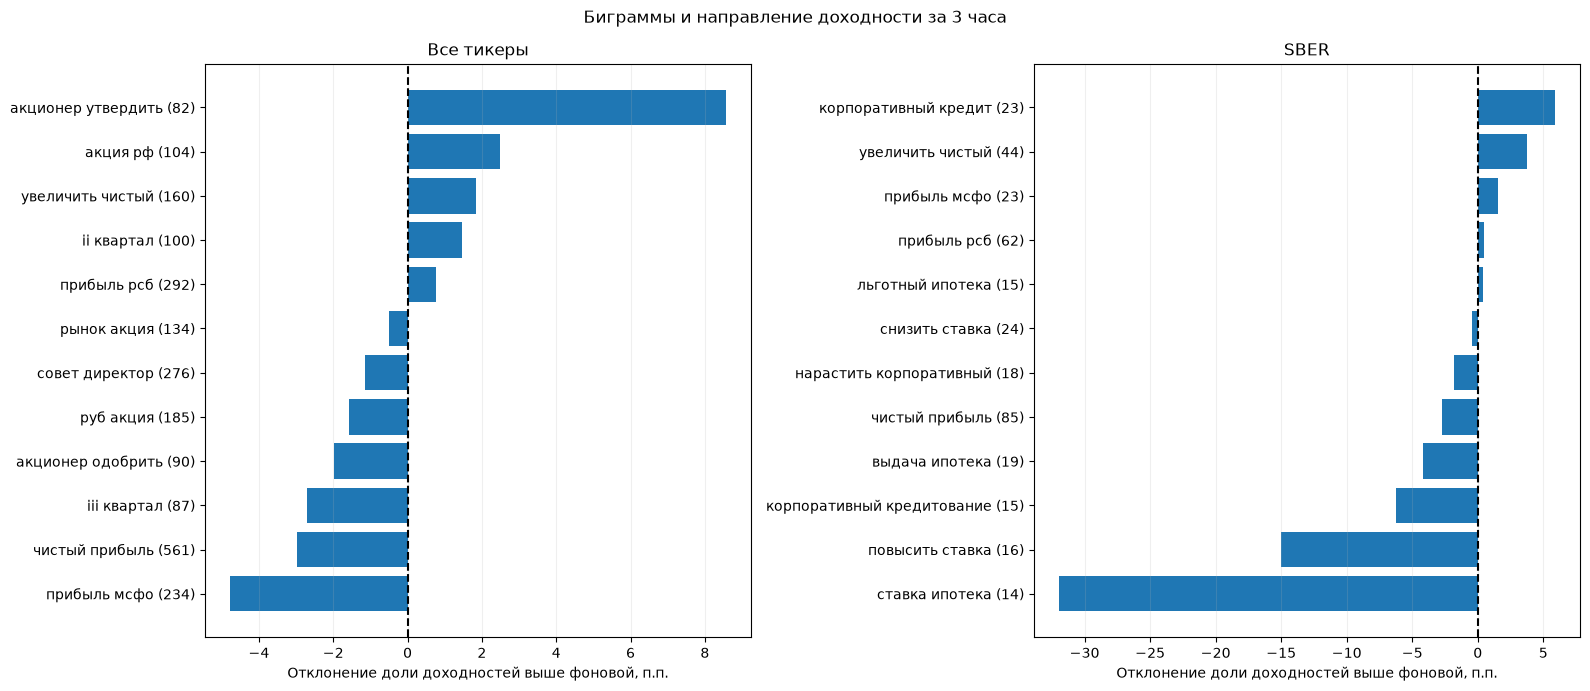

In [19]:
vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    min_df=5,
    binary=True
)

X = vectorizer.fit_transform(all_text_events["clean_title"])
terms = vectorizer.get_feature_names_out()
positive = all_text_events["positive"].to_numpy()

def get_bigram_stats(mask, min_count):
    X_part = X[mask]
    y_part = positive[mask]

    counts = np.asarray(X_part.sum(axis=0)).ravel()
    positive_counts = np.asarray(X_part.T @ y_part).ravel()

    stats = pd.DataFrame({
        "bigram": terms,
        "count": counts,
        "positive_pct": np.divide(
            positive_counts * 100,
            counts,
            out=np.zeros(len(counts), dtype=float),
            where=counts > 0
        )
    })

    stats = stats.loc[stats["count"] >= min_count].copy()
    stats["difference_pp"] = (
        stats["positive_pct"] - y_part.mean() * 100
    )

    return (
        stats.nlargest(BIGRAM_TOP_N, "count")
        .sort_values("difference_pp")
    )

global_mask = np.ones(len(all_text_events), dtype=bool)
ticker_mask = all_text_events["ticker"].eq(PLOT_TICKER).to_numpy()

global_stats = get_bigram_stats(
    global_mask, BIGRAM_GLOBAL_MIN_COUNT
)
ticker_stats = get_bigram_stats(
    ticker_mask, BIGRAM_TICKER_MIN_COUNT
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, stats, title in [
    (axes[0], global_stats, "Все тикеры"),
    (axes[1], ticker_stats, PLOT_TICKER)
]:
    ax.barh(
        stats["bigram"] + " (" + stats["count"].astype(str) + ")",
        stats["difference_pp"]
    )
    ax.axvline(0, color="black", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Отклонение доли доходностей выше фоновой, п.п.")
    ax.grid(axis="x", alpha=0.2)

plt.suptitle("Биграммы и направление доходности за 3 часа")
plt.tight_layout()
plt.show()

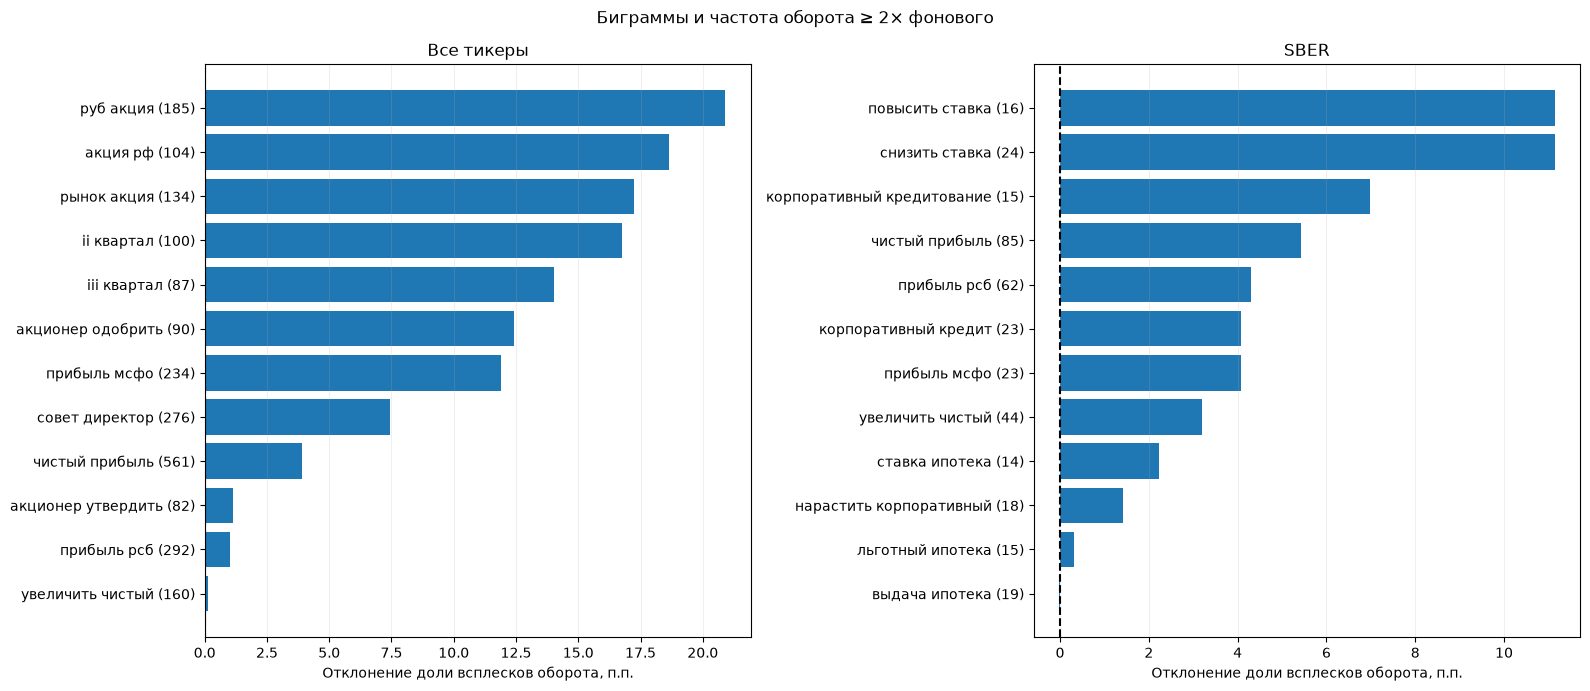

In [20]:
TURNOVER_TEXT_THRESHOLD = 2

turnover_baseline = (
    background.groupby(["ticker", "year", "hour"])["turnover_mln_rub"]
    .agg(
        baseline_turnover="median",
        turnover_baseline_count="count"
    )
)

turnover_text = all_text_events.join(
    turnover_baseline,
    on=["ticker", "year", "hour"]
)

valid = (
    turnover_text["turnover_baseline_count"].ge(MIN_BASELINE_COUNT)
    & turnover_text["baseline_turnover"].gt(0)
    & turnover_text["turnover_mln_rub"].notna()
).to_numpy()

turnover_text = turnover_text.loc[valid].reset_index(drop=True)
X_turnover = X[valid]

turnover_spike = (
    turnover_text["turnover_mln_rub"]
    / turnover_text["baseline_turnover"]
    >= TURNOVER_TEXT_THRESHOLD
).astype(int).to_numpy()

def turnover_bigram_stats(mask, min_count):
    X_part = X_turnover[mask]
    y_part = turnover_spike[mask]

    counts = np.asarray(X_part.sum(axis=0)).ravel()
    spikes = np.asarray(X_part.T @ y_part).ravel()

    stats = pd.DataFrame({
        "bigram": terms,
        "count": counts,
        "spike_pct": np.divide(
            spikes * 100,
            counts,
            out=np.zeros(len(counts), dtype=float),
            where=counts > 0
        )
    })

    stats = stats.loc[
        stats["count"] >= min_count
    ].nlargest(BIGRAM_TOP_N, "count").copy()

    stats["difference_pp"] = (
        stats["spike_pct"] - y_part.mean() * 100
    )

    return stats.sort_values("difference_pp")

global_stats_turnover = turnover_bigram_stats(
    np.ones(len(turnover_text), dtype=bool),
    BIGRAM_GLOBAL_MIN_COUNT
)

ticker_mask_turnover = turnover_text["ticker"].eq(PLOT_TICKER).to_numpy()

ticker_stats_turnover = turnover_bigram_stats(
    ticker_mask_turnover,
    BIGRAM_TICKER_MIN_COUNT
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, stats, title in [
    (axes[0], global_stats_turnover, "Все тикеры"),
    (axes[1], ticker_stats_turnover, PLOT_TICKER)
]:
    ax.barh(
        stats["bigram"] + " (" + stats["count"].astype(str) + ")",
        stats["difference_pp"]
    )
    ax.axvline(0, color="black", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Отклонение доли всплесков оборота, п.п.")
    ax.grid(axis="x", alpha=0.2)

plt.suptitle(
    f"Биграммы и частота оборота ≥ {TURNOVER_TEXT_THRESHOLD}× фонового"
)
plt.tight_layout()
plt.show()

На графиках видно, что отдельные биграммы связаны с различиями в направлении доходности и частоте всплесков оборота. Причём для разных акций набор таких выражений отличается. В частности, у Сбербанка новости об изменении ставок показывают заметные отклонения. При этом выборки по отдельным биграммам небольшие, поэтому делать однозначные выводы о влиянии слов на цену пока нельзя

## Общий вывод

После публикации новостей абсолютная доходность акций выше фоновой на 15–26% в зависимости от горизонта. При этом с увеличением горизонта разница снижается.

По оборотам различия еще заметнее. Медианный оборот после новостей выше фонового на 35%, а пятикратные всплески встречаются примерно в 2,5 раза чаще.

Анализ биграмм также показал различия в доходности и оборотах в зависимости от содержания заголовков, хотя для некоторых выражений наблюдений недостаточно.

В целом результаты указывают на связь новостей с рыночной активностью, однако установить причинное влияние в рамках EDA нельзя.